In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf, adfuller, kpss

warnings.filterwarnings('ignore')

# Configuración de estilo visual para gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (13, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

## a) Conteo de huecos y tratamiento mediante MICE

In [ ]:
# 1. Carga del conjunto de datos y pivotado para estación UIZ
df = pd.read_csv('contaminantes_N5/contaminantes_2026.csv')

uiz_raw = df[df['id_station'] == 'UIZ'].pivot(index='date', columns='id_parameter', values='valor')
uiz_raw.index = pd.to_datetime(uiz_raw.index)
uiz_raw = uiz_raw.sort_index()

# 2. Reindexado temporal estricto para asegurar continuidad horaria
# Del 2026-01-01 00:00 al 2026-02-28 23:00 (59 días x 24 horas = 1,416 horas)
full_index = pd.date_range(start='2026-01-01 00:00:00', end='2026-02-28 23:00:00', freq='h')
uiz = uiz_raw.reindex(full_index)

# 3. Conteo de huecos en O3 y contaminantes
total_hours = len(uiz)
missing_o3 = uiz['O3'].isna().sum()
pct_missing_o3 = (missing_o3 / total_hours) * 100

print("=" * 75)
print("REPORTE DE COBERTURA TEMPORAL Y FALTANTES — ESTACIÓN UIZ")
print("=" * 75)
print(f"Periodo:         {uiz.index.min()} al {uiz.index.max()}")
print(f"Total de horas calendario:  {total_hours} horas (59 días)")
print(f"Mediciones válidas en O3:   {total_hours - missing_o3} horas ({(1 - missing_o3/total_hours)*100:.2f}%)")
print(f"Huecos / Faltantes en O3:   {missing_o3} horas ({pct_missing_o3:.2f}%)")
print("=" * 75)

# 4. Análisis de longitud de las rachas consecutivas de huecos
is_na = uiz['O3'].isna()
blocks = (~is_na).cumsum()[is_na]
gap_sizes = blocks.value_counts()

print(f"\nNúmero total de eventos/rachas de desconexión en O3: {len(gap_sizes)}")
print(f"Racha promedio de desconexión: {gap_sizes.mean():.2f} horas consecutivas")
print(f"Racha máxima de desconexión:   {gap_sizes.max()} horas consecutivas")
print(f"Rachas de 1 sola hora:         {(gap_sizes == 1).sum()} ({((gap_sizes == 1).sum()/len(gap_sizes))*100:.1f}% de los eventos)")
print(f"Rachas menores o iguales a 4h: {(gap_sizes <= 4).sum()} ({((gap_sizes <= 4).sum()/len(gap_sizes))*100:.1f}% de los eventos)")

REPORTE DE COBERTURA TEMPORAL Y FALTANTES — ESTACIÓN UIZ
Periodo de estudio:         2026-01-01 00:00:00 al 2026-02-28 23:00:00
Total de horas calendario:  1416 horas (59 días)
Mediciones válidas en O3:   1291 horas (91.17%)
Huecos / Faltantes en O3:   125 horas (8.83%)

Número total de eventos/rachas de desconexión en O3: 34
Racha promedio de desconexión: 3.68 horas consecutivas
Racha máxima de desconexión:   20 horas consecutivas
Rachas de 1 sola hora:         19 (55.9% de los eventos)
Rachas menores o iguales a 4h: 28 (82.4% de los eventos)


EVALUACIÓN DE LA IMPUTACIÓN CON MICE
Faltantes en O3 antes del tratamiento: 125
Faltantes en O3 después del tratamiento: 0
Media O3 original: 26.23 ppb  | Media O3 post-MICE: 25.36 ppb
Desv. Est. original: 25.01 ppb | Desv. Est. post-MICE: 24.59 ppb


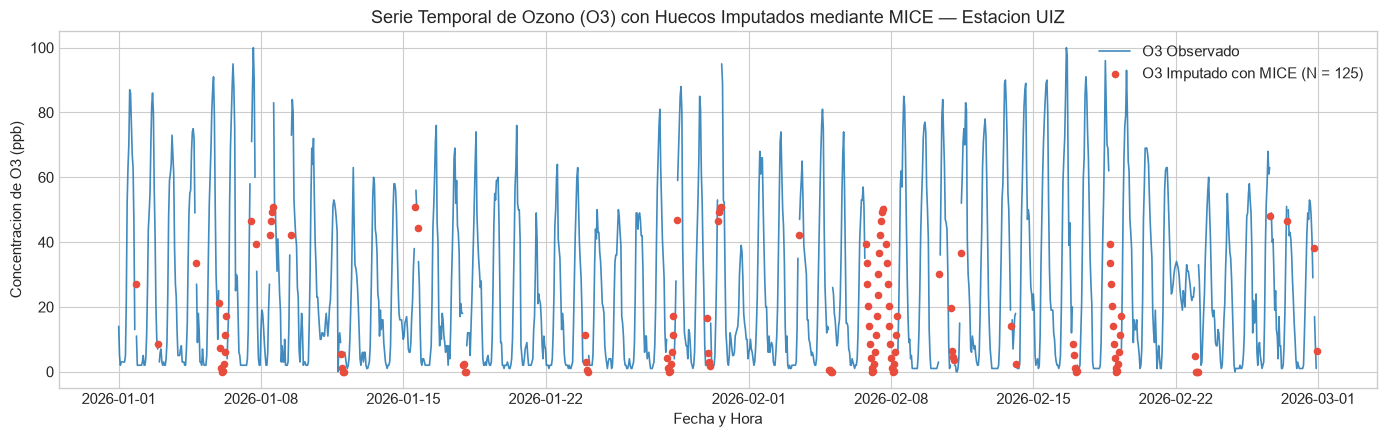

In [ ]:
# 5. Tratamiento de huecos mediante MICE (IterativeImputer)
# Añadimos variables temporales del ciclo diurno (seno y coseno de la hora)
df_mice = uiz.copy()
hour_rad = 2 * np.pi * df_mice.index.hour / 24.0
df_mice['sin_hour'] = np.sin(hour_rad)
df_mice['cos_hour'] = np.cos(hour_rad)

# Configuración del algoritmo MICE:
# Estrategia inicial con media
imputer_mice = IterativeImputer(
    estimator=BayesianRidge(),
    initial_strategy='mean',
    max_iter=15,
    random_state=42
)

# Ajuste e imputación
imputed_matrix = imputer_mice.fit_transform(df_mice)
uiz_imputed = pd.DataFrame(imputed_matrix, index=df_mice.index, columns=df_mice.columns)

# Serie limpia final de Ozono (restringida a valores no negativos)
o3_series = uiz_imputed['O3'].clip(lower=0)

print("=" * 75)
print("EVALUACIÓN DE LA IMPUTACIÓN CON MICE")
print("=" * 75)
print(f"Faltantes en O3 antes del tratamiento: {uiz['O3'].isna().sum()}")
print(f"Faltantes en O3 después del tratamiento: {o3_series.isna().sum()}")
print(f"Media O3 original: {uiz['O3'].mean():.2f} ppb  | Media O3 post-MICE: {o3_series.mean():.2f} ppb")
print(f"Desv. Est. original: {uiz['O3'].std():.2f} ppb | Desv. Est. post-MICE: {o3_series.std():.2f} ppb")
print("=" * 75)

# Visualización: Serie observada vs valores imputados
plt.figure(figsize=(14, 4.5))
plt.plot(uiz.index, uiz['O3'], label='O3 Observado', color='#1f77b4', lw=1.2, alpha=0.85)
mask_na = uiz['O3'].isna()
plt.scatter(
    uiz.index[mask_na], 
    o3_series[mask_na], 
    color='#e74c3c', 
    s=20, 
    label=f'O3 Imputado con MICE (N = {missing_o3})', 
    zorder=5
)
plt.title('Serie Temporal de Ozono (O3) con Huecos Imputados mediante MICE — Estacion UIZ')
plt.ylabel('Concentracion de O3 (ppb)')
plt.xlabel('Fecha y Hora')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## b) Gráfica de la serie y su ACF hasta 72 h

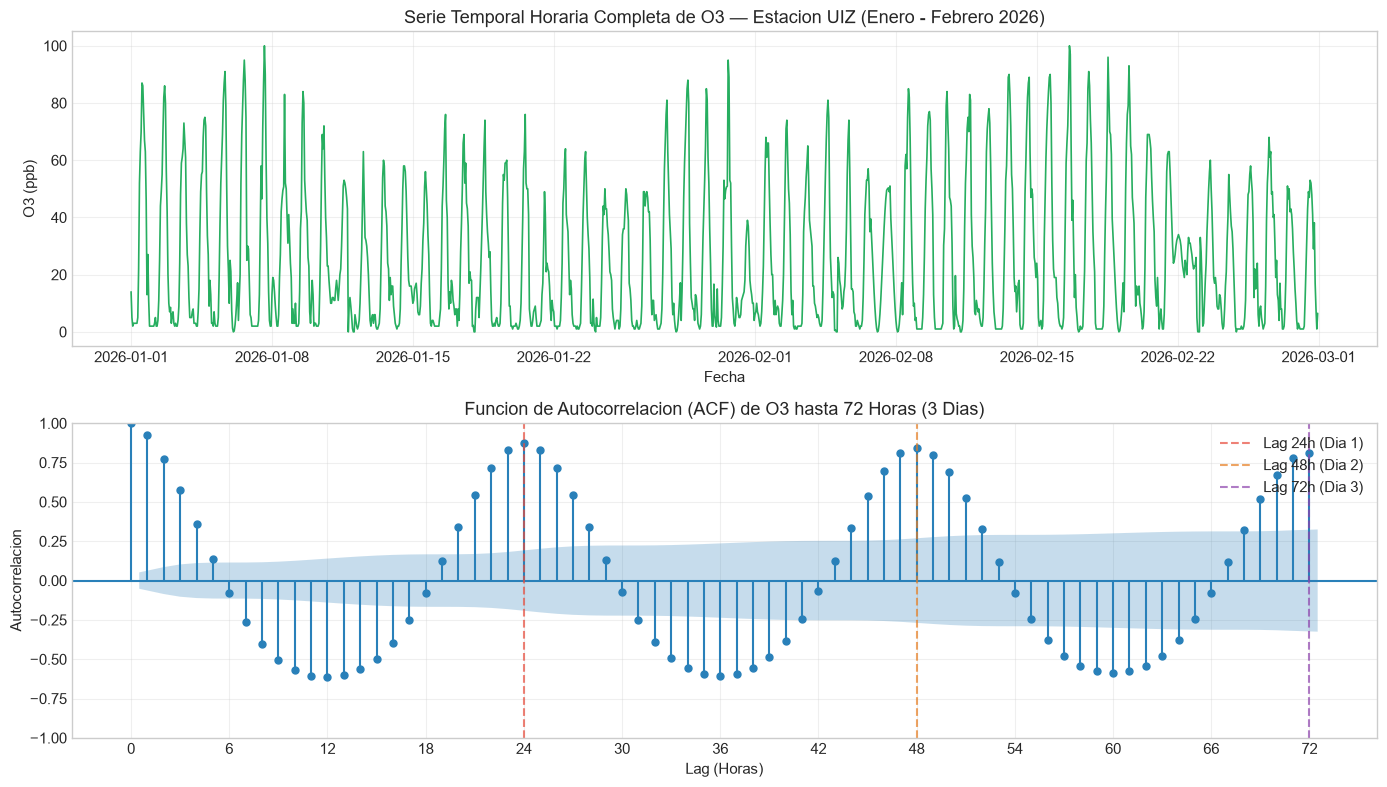

Valores cuantitativos de la Función de Autocorrelación (ACF):
  • Lag  1 horas:  rho_01 =  0.9220
  • Lag  2 horas:  rho_02 =  0.7709
  • Lag  6 horas:  rho_06 = -0.0773
  • Lag 12 horas:  rho_12 = -0.6147
  • Lag 24 horas:  rho_24 =  0.8726
  • Lag 36 horas:  rho_36 = -0.6055
  • Lag 48 horas:  rho_48 =  0.8446
  • Lag 60 horas:  rho_60 = -0.5859
  • Lag 72 horas:  rho_72 =  0.8132


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# 1. Serie temporal completa de O3
axes[0].plot(o3_series.index, o3_series, color='#27ae60', lw=1.2)
axes[0].set_title('Serie Temporal Horaria Completa de O3 — Estacion UIZ (Enero - Febrero 2026)')
axes[0].set_ylabel('O3 (ppb)')
axes[0].set_xlabel('Fecha')
axes[0].grid(True, alpha=0.3)

# 2. Función de Autocorrelación (ACF) hasta 72 horas
plot_acf(o3_series, lags=72, ax=axes[1], alpha=0.05, color='#2980b9', vlines_kwargs={'colors': '#2980b9', 'lw': 1.5})
axes[1].set_title('Funcion de Autocorrelacion (ACF) de O3 hasta 72 Horas (3 Dias)')
axes[1].set_xlabel('Lag (Horas)')
axes[1].set_ylabel('Autocorrelacion')
axes[1].set_xticks(range(0, 73, 6))
axes[1].axvline(24, color='#e74c3c', linestyle='--', alpha=0.7, label='Lag 24h (Dia 1)')
axes[1].axvline(48, color='#e67e22', linestyle='--', alpha=0.7, label='Lag 48h (Dia 2)')
axes[1].axvline(72, color='#8e44ad', linestyle='--', alpha=0.7, label='Lag 72h (Dia 3)')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Imprimir valores puntuales del ACF en retardos clave
acf_vals = acf(o3_series, nlags=72)
print("Valores cuantitativos de la Función de Autocorrelación (ACF):")
for lag in [1, 2, 6, 12, 24, 36, 48, 60, 72]:
    print(f"  • Lag {lag:2d} horas:  rho_{lag:02d} = {acf_vals[lag]:>7.4f}")

## c) Pruebas de Raíz Unitaria: ADF y KPSS

In [5]:
# Función general para ejecutar y documentar las pruebas ADF y KPSS
def test_stationarity(series, label):
    s = series.dropna()
    adf_res = adfuller(s, autolag='AIC')
    kpss_res = kpss(s, regression='c', nlags='auto')
    
    adf_stat, adf_p, adf_lags, adf_nobs, adf_crit, _ = adf_res
    kpss_stat, kpss_p, kpss_lags, kpss_crit = kpss_res
    
    print("=" * 80)
    print(f"DIAGNÓSTICO ESTADÍSTICO DE ESTACIONARIEDAD: {label.upper()}")
    print("=" * 80)
    print(f"Varianza total de la serie: {s.var():.4f}")
    print(f"Longitud de la serie analizada: {len(s)} observaciones")
    
    print("\n1. Prueba Augmented Dickey-Fuller (ADF):")
    print(f"   • Estadístico de prueba: {adf_stat:>9.4f}")
    print(f"   • p-value:                {adf_p:>9.4e}")
    print(f"   • Lags óptimos (AIC):    {adf_lags}")
    print(f"   • Valor crítico al 5%:   {adf_crit['5%']:>9.4f}")
    decision_adf = "RECHAZA H0 -> Serie sin raíz unitaria (Estacionaria)" if adf_p < 0.05 else "NO RECHAZA H0 -> Hay raíz unitaria (No estacionaria)"
    print(f"   -> Decisión ADF: {decision_adf}")
    
    print("\n2. Prueba KPSS (Kwiatkowski-Phillips-Schmidt-Shin):")
    print(f"   • Estadístico de prueba: {kpss_stat:>9.4f}")
    print(f"   • p-value:                {kpss_p:>9.4f}")
    print(f"   • Lags de truncamiento:  {kpss_lags}")
    print(f"   • Valor crítico al 5%:   {kpss_crit['5%']:>9.4f}")
    decision_kpss = "RECHAZA H0 -> No es estacionaria" if kpss_p < 0.05 else "NO RECHAZA H0 -> Es estacionaria"
    print(f"   -> Decisión KPSS: {decision_kpss}")
    print("=" * 80)
    
    diag_final = "Estacionaria" if (adf_p < 0.05 and kpss_p >= 0.05) else (
        "Estacional / Conflicto" if (adf_p < 0.05 and kpss_p < 0.05) else "No Estacionaria"
    )
    
    return {
        'Serie': label,
        'Varianza': s.var(),
        'ADF Stat': adf_stat,
        'ADF p-value': adf_p,
        'KPSS Stat': kpss_stat,
        'KPSS p-value': kpss_p,
        'Diagnóstico': diag_final
    }

# Ejecución sobre la serie original imputada
res_c = test_stationarity(o3_series, "Serie Original Imputada (O3)")

DIAGNÓSTICO ESTADÍSTICO DE ESTACIONARIEDAD: SERIE ORIGINAL IMPUTADA (O3)
Varianza total de la serie: 604.7120
Longitud de la serie analizada: 1416 observaciones

1. Prueba Augmented Dickey-Fuller (ADF):
   • Estadístico de prueba:   -3.2596
   • p-value:                1.6786e-02
   • Lags óptimos (AIC):    23
   • Valor crítico al 5%:     -2.8636
   -> Decisión ADF: RECHAZA H0 -> Serie sin raíz unitaria (Estacionaria)

2. Prueba KPSS (Kwiatkowski-Phillips-Schmidt-Shin):
   • Estadístico de prueba:    0.5212
   • p-value:                   0.0369
   • Lags de truncamiento:  19
   • Valor crítico al 5%:      0.4630
   -> Decisión KPSS: RECHAZA H0 -> No es estacionaria


## d) Restar la media de cada hora del día y repetir c)

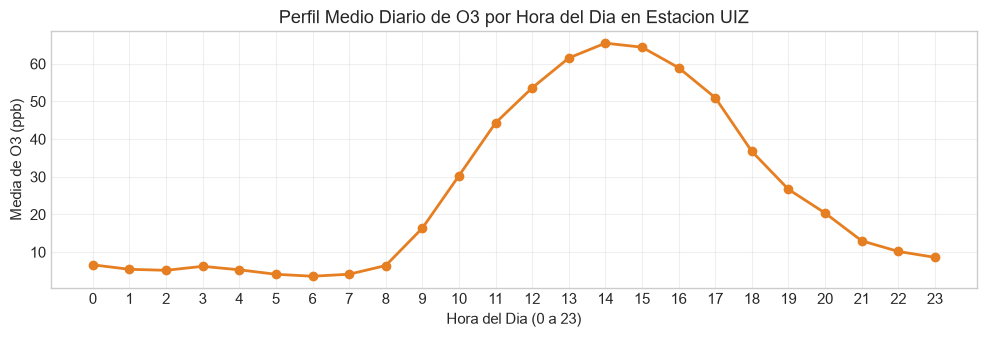

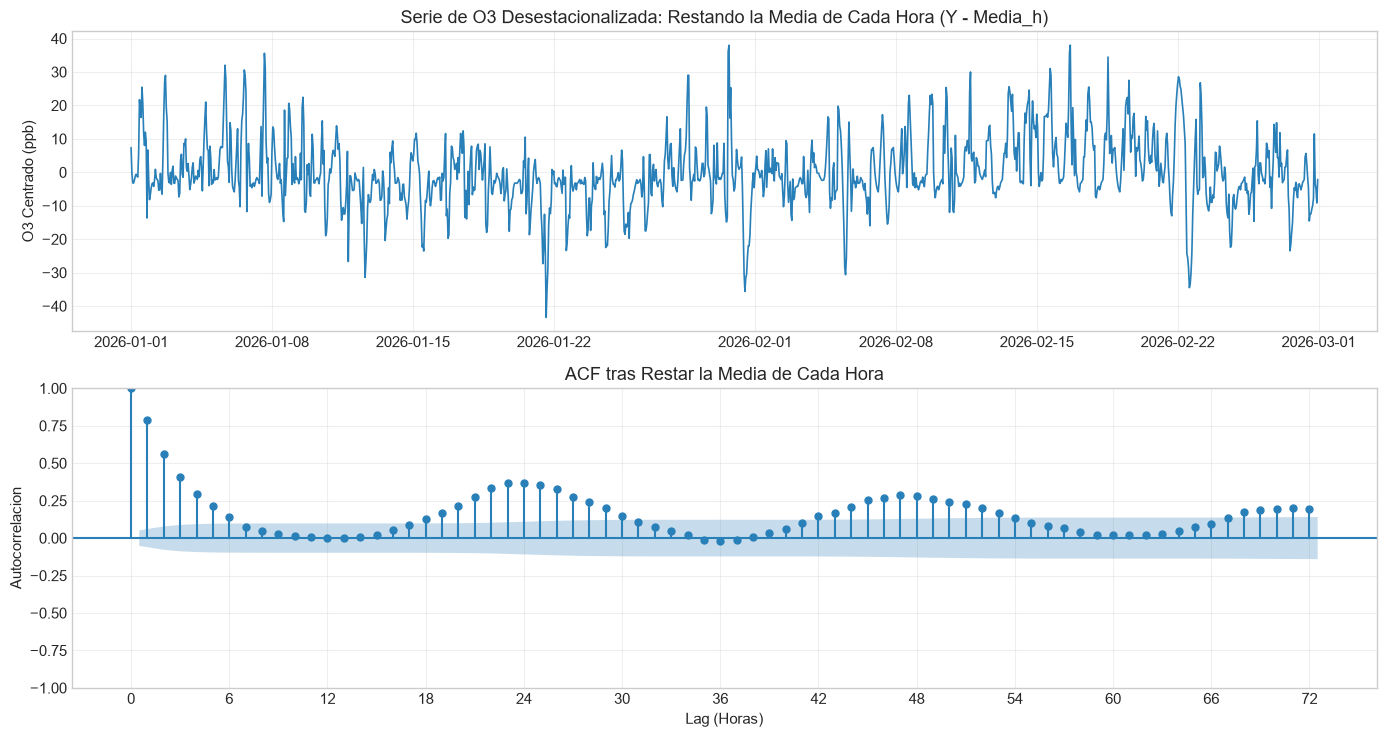

DIAGNÓSTICO ESTADÍSTICO DE ESTACIONARIEDAD: RESTANDO MEDIA POR HORA (D)
Varianza total de la serie: 105.4458
Longitud de la serie analizada: 1416 observaciones

1. Prueba Augmented Dickey-Fuller (ADF):
   • Estadístico de prueba:   -3.6561
   • p-value:                4.7744e-03
   • Lags óptimos (AIC):    24
   • Valor crítico al 5%:     -2.8636
   -> Decisión ADF: RECHAZA H0 -> Serie sin raíz unitaria (Estacionaria)

2. Prueba KPSS (Kwiatkowski-Phillips-Schmidt-Shin):
   • Estadístico de prueba:    0.7654
   • p-value:                   0.0100
   • Lags de truncamiento:  20
   • Valor crítico al 5%:      0.4630
   -> Decisión KPSS: RECHAZA H0 -> No es estacionaria


In [6]:
# 1. Cálculo del perfil medio horario (24 valores)
mean_by_hour = o3_series.groupby(o3_series.index.hour).transform('mean')
o3_deseason_hour = o3_series - mean_by_hour

# Gráfica del perfil medio diario
plt.figure(figsize=(10, 3.5))
profile_hour = o3_series.groupby(o3_series.index.hour).mean()
plt.plot(profile_hour.index, profile_hour.values, marker='o', color='#e67e22', lw=2)
plt.title('Perfil Medio Diario de O3 por Hora del Dia en Estacion UIZ')
plt.xlabel('Hora del Dia (0 a 23)')
plt.ylabel('Media de O3 (ppb)')
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Visualización de la serie y su ACF tras restar la media de cada hora
fig, axes = plt.subplots(2, 1, figsize=(14, 7.5))
axes[0].plot(o3_deseason_hour.index, o3_deseason_hour, color='#2980b9', lw=1.2)
axes[0].set_title('Serie de O3 Desestacionalizada: Restando la Media de Cada Hora (Y - Media_h)')
axes[0].set_ylabel('O3 Centrado (ppb)')
axes[0].grid(True, alpha=0.3)

plot_acf(o3_deseason_hour, lags=72, ax=axes[1], alpha=0.05, color='#2980b9', vlines_kwargs={'colors': '#2980b9', 'lw': 1.5})
axes[1].set_title('ACF tras Restar la Media de Cada Hora')
axes[1].set_xlabel('Lag (Horas)')
axes[1].set_ylabel('Autocorrelacion')
axes[1].set_xticks(range(0, 73, 6))
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Pruebas ADF y KPSS
res_d = test_stationarity(o3_deseason_hour, "Restando Media por Hora (d)")

## e) Restar la media de cada mes $\times$ hora y repetir c)

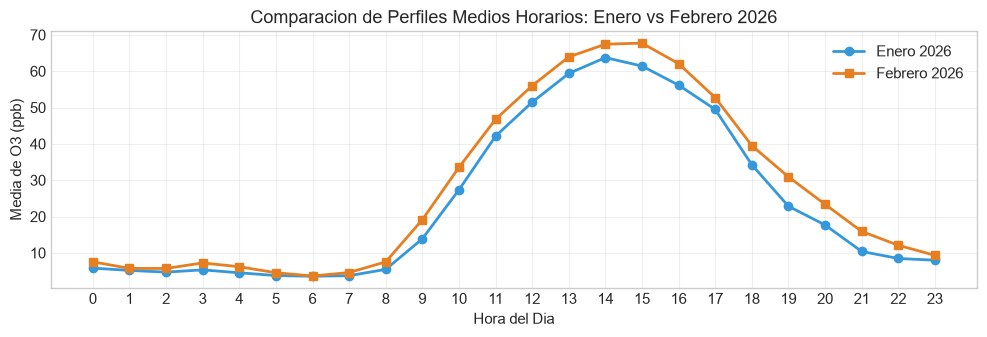

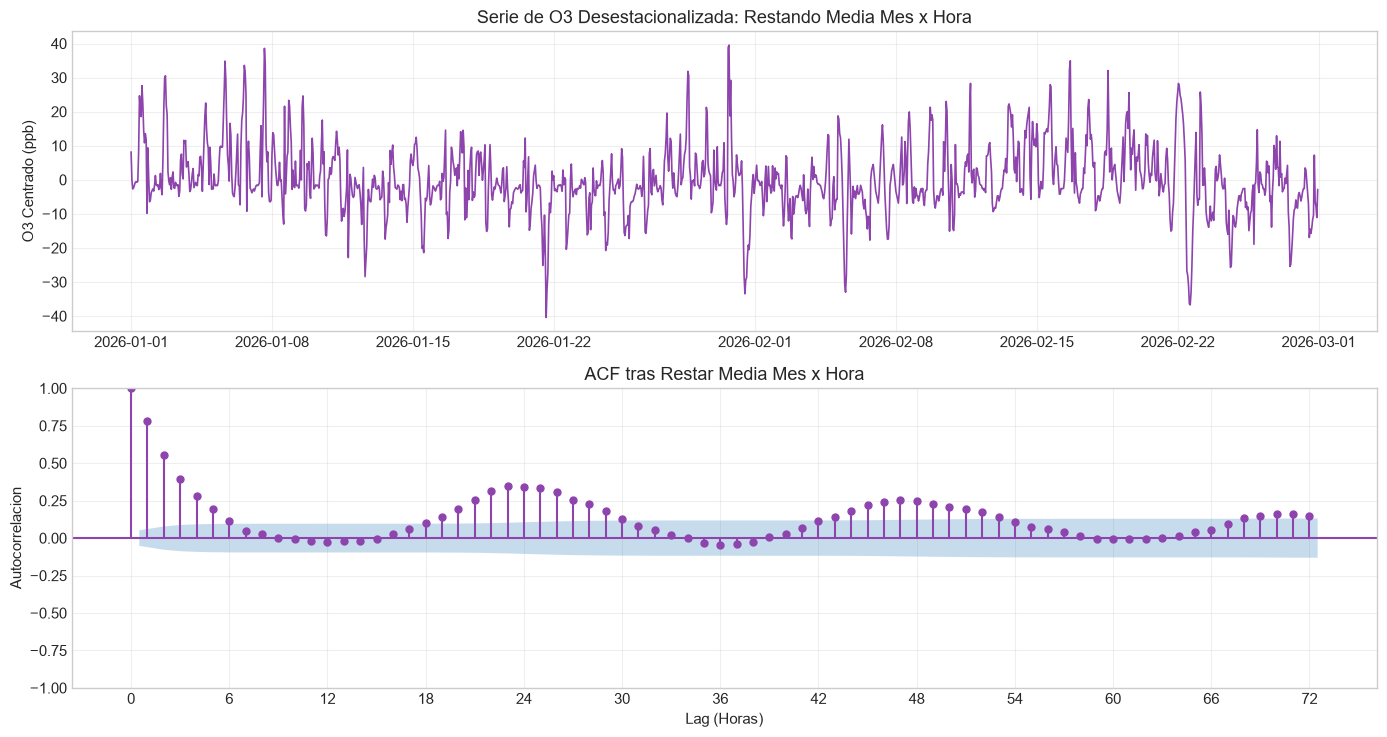

DIAGNÓSTICO ESTADÍSTICO DE ESTACIONARIEDAD: RESTANDO MEDIA MES X HORA (E)
Varianza total de la serie: 101.1302
Longitud de la serie analizada: 1416 observaciones

1. Prueba Augmented Dickey-Fuller (ADF):
   • Estadístico de prueba:   -3.8517
   • p-value:                2.4202e-03
   • Lags óptimos (AIC):    24
   • Valor crítico al 5%:     -2.8636
   -> Decisión ADF: RECHAZA H0 -> Serie sin raíz unitaria (Estacionaria)

2. Prueba KPSS (Kwiatkowski-Phillips-Schmidt-Shin):
   • Estadístico de prueba:    0.3956
   • p-value:                   0.0791
   • Lags de truncamiento:  19
   • Valor crítico al 5%:      0.4630
   -> Decisión KPSS: NO RECHAZA H0 -> Es estacionaria


In [7]:
# 1. Cálculo de medias por combinación [mes, hora]
mean_by_month_hour = o3_series.groupby([o3_series.index.month, o3_series.index.hour]).transform('mean')
o3_deseason_month_hour = o3_series - mean_by_month_hour

# Comparación gráfica del perfil diario de Enero vs Febrero
plt.figure(figsize=(10, 3.5))
perfil_ene = o3_series[o3_series.index.month == 1].groupby(o3_series[o3_series.index.month == 1].index.hour).mean()
perfil_feb = o3_series[o3_series.index.month == 2].groupby(o3_series[o3_series.index.month == 2].index.hour).mean()
plt.plot(perfil_ene.index, perfil_ene.values, marker='o', label='Enero 2026', color='#3498db', lw=2)
plt.plot(perfil_feb.index, perfil_feb.values, marker='s', label='Febrero 2026', color='#e67e22', lw=2)
plt.title('Comparacion de Perfiles Medios Horarios: Enero vs Febrero 2026')
plt.xlabel('Hora del Dia')
plt.ylabel('Media de O3 (ppb)')
plt.xticks(range(0, 24))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Visualización de la serie y su ACF tras restar media mes x hora
fig, axes = plt.subplots(2, 1, figsize=(14, 7.5))
axes[0].plot(o3_deseason_month_hour.index, o3_deseason_month_hour, color='#8e44ad', lw=1.2)
axes[0].set_title('Serie de O3 Desestacionalizada: Restando Media Mes x Hora')
axes[0].set_ylabel('O3 Centrado (ppb)')
axes[0].grid(True, alpha=0.3)

plot_acf(o3_deseason_month_hour, lags=72, ax=axes[1], alpha=0.05, color='#8e44ad', vlines_kwargs={'colors': '#8e44ad', 'lw': 1.5})
axes[1].set_title('ACF tras Restar Media Mes x Hora')
axes[1].set_xlabel('Lag (Horas)')
axes[1].set_ylabel('Autocorrelacion')
axes[1].set_xticks(range(0, 73, 6))
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Pruebas ADF y KPSS
res_e = test_stationarity(o3_deseason_month_hour, "Restando Media Mes x Hora (e)")

## f) Diferencia de 24 horas ($\Delta_{24} Y_t$), pruebas ADF/KPSS y comparación con e)

DIAGNÓSTICO ESTADÍSTICO DE ESTACIONARIEDAD: DIFERENCIA DE 24 HORAS (F)
Varianza total de la serie: 132.9016
Longitud de la serie analizada: 1392 observaciones

1. Prueba Augmented Dickey-Fuller (ADF):
   • Estadístico de prueba:   -8.9012
   • p-value:                1.1703e-14
   • Lags óptimos (AIC):    24
   • Valor crítico al 5%:     -2.8637
   -> Decisión ADF: RECHAZA H0 -> Serie sin raíz unitaria (Estacionaria)

2. Prueba KPSS (Kwiatkowski-Phillips-Schmidt-Shin):
   • Estadístico de prueba:    0.0355
   • p-value:                   0.1000
   • Lags de truncamiento:  15
   • Valor crítico al 5%:      0.4630
   -> Decisión KPSS: NO RECHAZA H0 -> Es estacionaria


,Varianza,ADF Stat,ADF p-value,KPSS Stat,KPSS p-value,Diagnóstico
Serie,,,,,,
Serie Original Imputada (O3),604.712029,-3.259566,1.678550e-02,0.521166,0.036900,Estacional / Conflicto
Restando Media por Hora (d),105.445814,-3.656120,4.774448e-03,0.765360,0.010000,Estacional / Conflicto
Restando Media Mes x Hora (e),101.130227,-3.851738,2.420181e-03,0.395602,0.079051,Estacionaria
Diferencia de 24 Horas (f),132.901620,-8.901168,1.170315e-14,0.035471,0.100000,Estacionaria



COMPARACIÓN CRÍTICA DE VARIANZAS: e) [Mes x Hora] vs f) [Diff 24h]
Varianza Serie Original:                604.71  (100.0%)
Varianza e) [Restando Mes x Hora]:       101.13  ( 16.7%)
Varianza f) [Diferencia de 24 Horas]:    132.90  ( 22.0%)
---------------------------------------------------------------------------
La varianza de f) es 31.77 unidades (+31.42%) MAYOR que la de e).


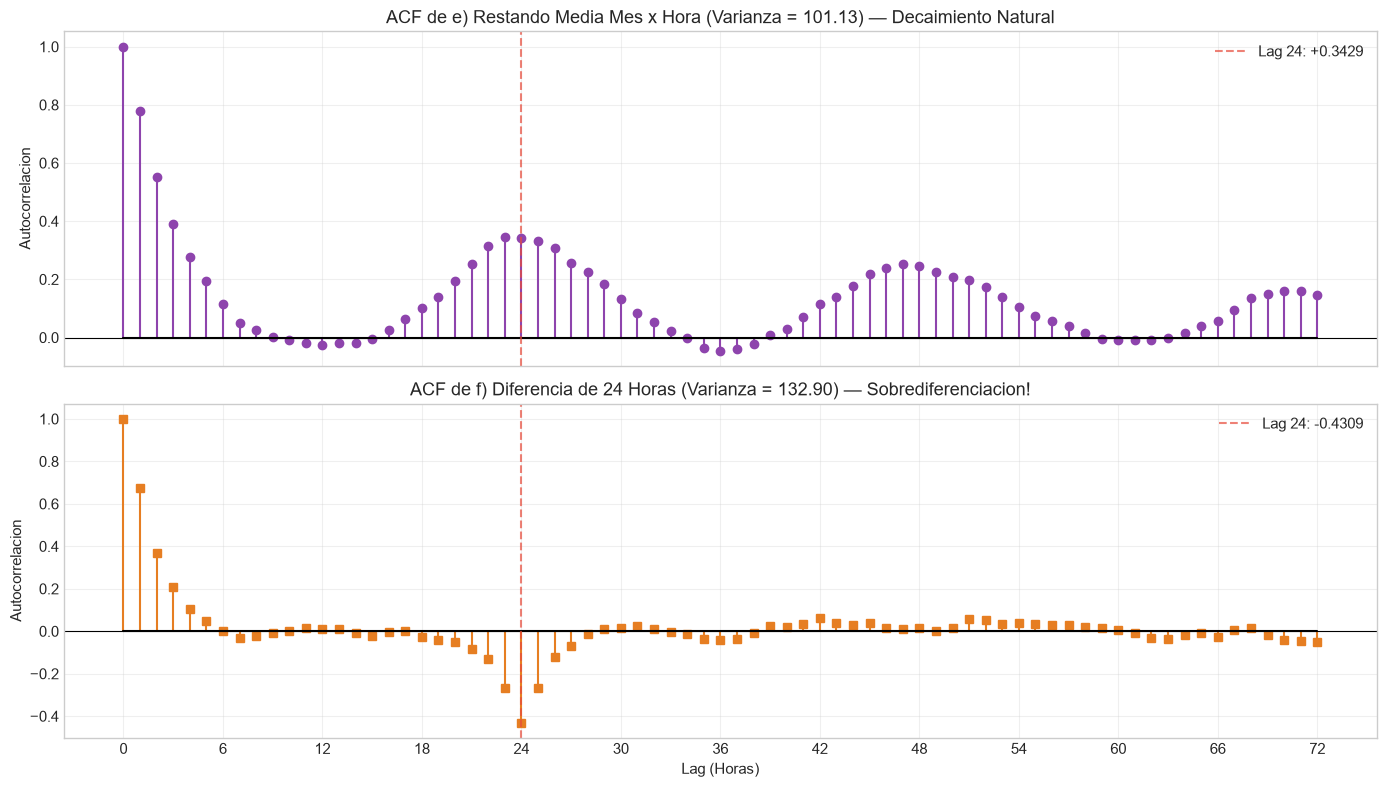

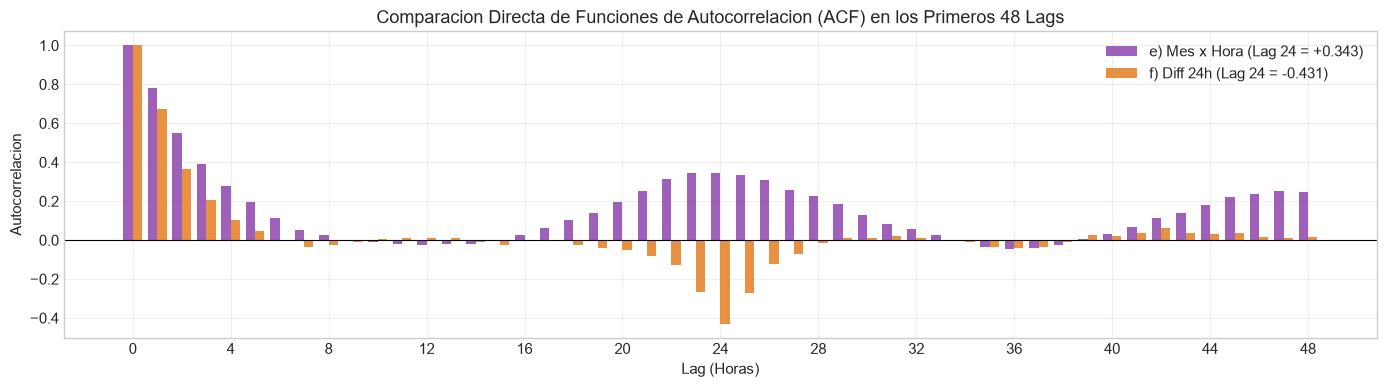

In [8]:
# 1. Aplicación de la diferencia de 24 horas
o3_diff24 = o3_series.diff(24).dropna()

# 2. Pruebas de estacionariedad para la serie diferenciada
res_f = test_stationarity(o3_diff24, "Diferencia de 24 Horas (f)")

# 3. Tabla comparativa general de todas las transformaciones
tabla_comparativa = pd.DataFrame([res_c, res_d, res_e, res_f]).set_index('Serie')
display(tabla_comparativa)

# 4. Comparación cuantitativa de varianzas
var_orig = o3_series.var()
var_e = o3_deseason_month_hour.var()
var_f = o3_diff24.var()

print("\n" + "=" * 75)
print("COMPARACIÓN CRÍTICA DE VARIANZAS: e) [Mes x Hora] vs f) [Diff 24h]")
print("=" * 75)
print(f"Varianza Serie Original:              {var_orig:>8.2f}  (100.0%)")
print(f"Varianza e) [Restando Mes x Hora]:     {var_e:>8.2f}  ({var_e/var_orig*100:>5.1f}%)")
print(f"Varianza f) [Diferencia de 24 Horas]:  {var_f:>8.2f}  ({var_f/var_orig*100:>5.1f}%)")
print("-" * 75)
incremento_var = ((var_f / var_e) - 1) * 100
print(f"La varianza de f) es {var_f - var_e:.2f} unidades (+{incremento_var:.2f}%) MAYOR que la de e).")
print("=" * 75)

# 5. Gráficas de los dos ACFs superpuestos para comparación directa
acf_e = acf(o3_deseason_month_hour, nlags=72)
acf_f = acf(o3_diff24, nlags=72)
lags_range = range(73)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Stem plot para e)
axes[0].stem(lags_range, acf_e, linefmt='#8e44ad', markerfmt='o', basefmt='k-')
axes[0].set_title(f'ACF de e) Restando Media Mes x Hora (Varianza = {var_e:.2f}) — Decaimiento Natural')
axes[0].set_ylabel('Autocorrelacion')
axes[0].axhline(0, color='black', lw=0.8)
axes[0].axvline(24, color='#e74c3c', linestyle='--', alpha=0.7, label=f'Lag 24: +{acf_e[24]:.4f}')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3)

# Stem plot para f)
axes[1].stem(lags_range, acf_f, linefmt='#e67e22', markerfmt='s', basefmt='k-')
axes[1].set_title(f'ACF de f) Diferencia de 24 Horas (Varianza = {var_f:.2f}) — Sobrediferenciacion!')
axes[1].set_ylabel('Autocorrelacion')
axes[1].set_xlabel('Lag (Horas)')
axes[1].axhline(0, color='black', lw=0.8)
axes[1].axvline(24, color='#e74c3c', linestyle='--', alpha=0.7, label=f'Lag 24: {acf_f[24]:.4f}')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.xticks(range(0, 73, 6))
plt.tight_layout()
plt.show()

# Comparativa de barras en los primeros 48 lags
plt.figure(figsize=(14, 4))
w = 0.38
plt.bar([l - w/2 for l in lags_range[:49]], acf_e[:49], width=w, label=f'e) Mes x Hora (Lag 24 = +{acf_e[24]:.3f})', color='#8e44ad', alpha=0.85)
plt.bar([l + w/2 for l in lags_range[:49]], acf_f[:49], width=w, label=f'f) Diff 24h (Lag 24 = {acf_f[24]:.3f})', color='#e67e22', alpha=0.85)
plt.title('Comparacion Directa de Funciones de Autocorrelacion (ACF) en los Primeros 48 Lags')
plt.xlabel('Lag (Horas)')
plt.ylabel('Autocorrelacion')
plt.axhline(0, color='black', lw=0.8)
plt.xticks(range(0, 49, 4))
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()